# 00 · Exploratory Data Analysis — litigation recovery on unsecured bad debt


The output is a clean client × period table saved to `data/processed/` for `01_target_definition`.

## 0. Setup

In [1]:
import os, sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore")

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = Path("/content/drive/MyDrive/Court-Recovery-Model")
else:
    PROJECT_DIR = Path(os.environ.get("PROJECT_DIR", "..")).resolve()

RAW_DIR = PROJECT_DIR / "data" / "raw"
PROC_DIR = PROJECT_DIR / "data" / "processed"
FIG_DIR = PROJECT_DIR / "reports" / "figures"
PROC_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
np.random.seed(SEED)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid", context="notebook")

FIXED_COST = 500
VAR_COST_RATE = 0.10
HORIZON = 24

def savefig(name):
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

print("Project dir:", PROJECT_DIR)
print("Raw files:", sorted(p.name for p in RAW_DIR.glob("*.csv")))

Mounted at /content/drive
Project dir: /content/drive/MyDrive/Court-Recovery-Model
Raw files: ['Features.csv', 'feature_dictionary.csv', 'loan_month_recovery.csv']


## 1. Load data and first look

In [2]:
rec = pd.read_csv(RAW_DIR / "loan_month_recovery.csv")
feat = pd.read_csv(RAW_DIR / "Features.csv")
fdict = pd.read_csv(RAW_DIR / "feature_dictionary.csv")

for name, df in [("loan_month_recovery", rec), ("Features", feat), ("feature_dictionary", fdict)]:
    print(f"{name:22s} rows={df.shape[0]:>7,}  cols={df.shape[1]:>3}  "
          f"memory={df.memory_usage(deep=True).sum() / 1e6:5.1f} MB")

feat = feat.rename(columns={"client_key": "CLIENT_KEY"})

PAY_COLS = [f"M{i:02d}_PAID" for i in range(1, HORIZON + 1)]
FEATURES = [c for c in feat.columns if c.startswith("feature_")]
print(f"\nPayment columns: {len(PAY_COLS)} (wide format), model features: {len(FEATURES)}")

loan_month_recovery    rows= 70,173  cols= 33  memory= 28.2 MB
Features               rows= 29,763  cols= 52  memory= 13.8 MB
feature_dictionary     rows=     50  cols=  4  memory=  0.0 MB

Payment columns: 24 (wide format), model features: 50


In [3]:
def profile(df, cols=None):
    cols = list(cols) if cols is not None else list(df.columns)
    return pd.DataFrame({
        "dtype": df[cols].dtypes.astype(str),
        "n_unique": df[cols].nunique(),
        "missing_pct": (df[cols].isna().mean() * 100).round(2),
    })

display(profile(rec, [c for c in rec.columns if c not in PAY_COLS]))

,dtype,n_unique,missing_pct
LOAN_KEY,int64,70173,0.000
CLIENT_KEY,int64,22000,0.000
PERIOD,object,38,0.000
DEAL_CCY,object,2,0.000
OUTST_AT_TRIAL,float64,65214,0.000
DEAL_PRINCIPAL_IN_GEL,float64,66539,0.000
HAS_COLLATERAL,int64,2,0.000
COLLATERAL_TYPE,object,4,0.000
MONTHS_OBSERVED,int64,19,0.000


## 2. Grain, keys and join coverage

The court decision is taken at **client level**, while recovery is recorded per **loan**.
A client can also be sent to court in more than one period, so the modelling unit is **client × PERIOD**.

In [4]:
n_cp = rec[["CLIENT_KEY", "PERIOD"]].drop_duplicates().shape[0]
print(f"Loan rows:            {len(rec):,}  (duplicate LOAN_KEY: {rec.LOAN_KEY.duplicated().sum()})")
print(f"Unique clients:       {rec.CLIENT_KEY.nunique():,}")
print(f"Client-period pairs:  {n_cp:,}")
print(f"Feature rows:         {len(feat):,}  (unique client-period: "
      f"{feat[['CLIENT_KEY', 'PERIOD']].drop_duplicates().shape[0]:,})")

print("\nNumber of distinct court periods per client:")
display(rec.groupby("CLIENT_KEY").PERIOD.nunique().value_counts().sort_index().rename("clients").to_frame())

print("Loans per client-period:")
display(rec.groupby(["CLIENT_KEY", "PERIOD"]).size().value_counts().sort_index().rename("client_periods").to_frame().T)

join = (rec[["CLIENT_KEY", "PERIOD"]].drop_duplicates()
        .merge(feat[["CLIENT_KEY", "PERIOD"]], how="outer", indicator=True))
print("Join coverage recovery ↔ features:")
display(join["_merge"].value_counts().to_frame("client_periods"))

Loan rows:            70,173  (duplicate LOAN_KEY: 0)
Unique clients:       22,000
Client-period pairs:  29,763
Feature rows:         29,763  (unique client-period: 29,763)

Number of distinct court periods per client:


,clients
PERIOD,
1,14237
2,7763


Loans per client-period:


,1,2,3,4,5,6,7
client_periods,7606,10458,7043,3205,1081,293,77


Join coverage recovery ↔ features:


,client_periods
_merge,
both,29763
left_only,0
right_only,0


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


## 3. Data quality of the recovery history

In [5]:
rec["PAID_TOTAL"] = rec[PAY_COLS].sum(axis=1)

observed = rec[PAY_COLS].notna().values
expected = np.arange(HORIZON)[None, :] < rec["MONTHS_OBSERVED"].values[:, None]

checks = {
    "MONTHS_OBSERVED equals number of non-null months": (observed.sum(1) == rec.MONTHS_OBSERVED).all(),
    "Missing months only AFTER observation window (pure right-censoring)": (observed == expected).all(),
    "Negative monthly payments": int((rec[PAY_COLS] < 0).sum().sum()),
    "Loans with total paid > outstanding": int((rec.PAID_TOTAL > rec.OUTST_AT_TRIAL + 1e-6).sum()),
    "Loans with OUTST_AT_TRIAL <= 0": int((rec.OUTST_AT_TRIAL <= 0).sum()),
    "Loans with outstanding > original principal": int((rec.OUTST_AT_TRIAL > rec.DEAL_PRINCIPAL_IN_GEL).sum()),
    "Fully duplicated rows": int(rec.duplicated().sum()),
}
display(pd.Series(checks, name="result").to_frame())

print("Currency:")
display(rec.DEAL_CCY.value_counts().to_frame("loans").T)
print("Collateral flag vs type (consistency):")
display(pd.crosstab(rec.HAS_COLLATERAL, rec.COLLATERAL_TYPE))
display(rec[["OUTST_AT_TRIAL", "DEAL_PRINCIPAL_IN_GEL", "PAID_TOTAL"]]
        .describe(percentiles=[.01, .25, .5, .75, .95, .99]).T)

,result
MONTHS_OBSERVED equals number of non-null months,True
Missing months only AFTER observation window (pure right-censoring),True
Negative monthly payments,0
Loans with total paid > outstanding,0
Loans with OUTST_AT_TRIAL <= 0,40
Loans with outstanding > original principal,0
Fully duplicated rows,0


Currency:


DEAL_CCY,GEL,USD
loans,70155,18


Collateral flag vs type (consistency):


COLLATERAL_TYPE,DEPOSIT,NONE,REAL_ESTATE,VEHICLE
HAS_COLLATERAL,,,,
0,0,60267,0,0
1,2539,0,3447,3920


,count,mean,std,min,1%,25%,50%,75%,95%,99%,max
OUTST_AT_TRIAL,"70,173.000","3,160.193","5,305.346",0.000,109.496,753.320,"1,635.400","3,544.630","10,783.672","23,670.805","220,903.700"
DEAL_PRINCIPAL_IN_GEL,"70,173.000","4,391.655","7,619.382",51.120,144.615,"1,019.110","2,236.720","4,861.340","15,030.176","33,477.886","374,193.830"
PAID_TOTAL,"70,173.000",376.966,"1,459.504",0.000,0.000,0.000,4.540,211.450,"1,835.958","5,522.487","114,995.560"


## 4. Cohorts and censoring

Implied data snapshot month: ['2026-08']
Fully observed cohorts: 20 (2023-01 … 2024-08)


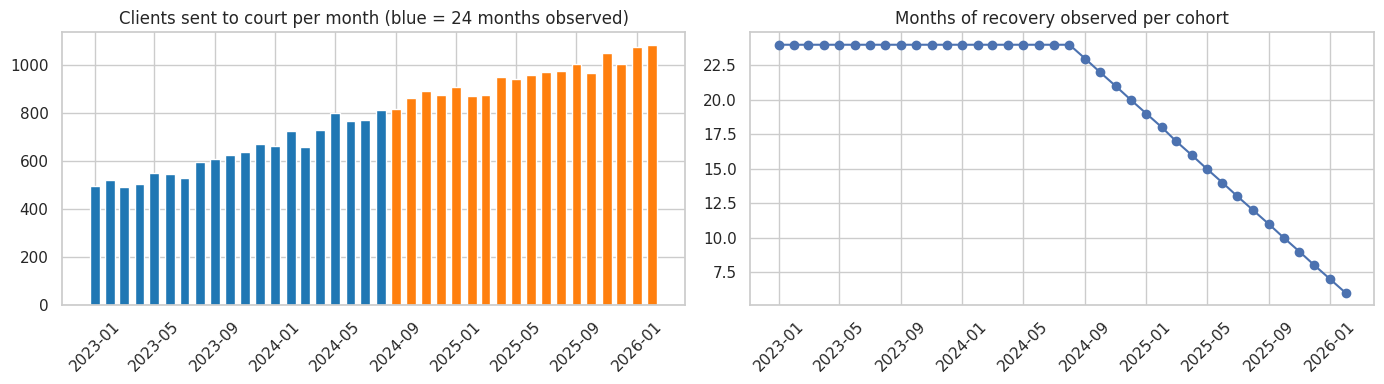

In [6]:
rec["PERIOD_DT"] = pd.to_datetime(rec.PERIOD, format="%Y/%m")
cens = rec[rec.MONTHS_OBSERVED < HORIZON]
cutoff = (cens.PERIOD_DT.dt.to_period("M") + cens.MONTHS_OBSERVED).unique()
print("Implied data snapshot month:", [str(p) for p in cutoff])

coh = rec.groupby("PERIOD_DT").agg(loans=("LOAN_KEY", "size"),
                                   clients=("CLIENT_KEY", "nunique"),
                                   months_observed=("MONTHS_OBSERVED", "max"))
coh["fully_observed"] = coh.months_observed == HORIZON
print(f"Fully observed cohorts: {coh.fully_observed.sum()} "
      f"({coh.index[coh.fully_observed].min():%Y-%m} … {coh.index[coh.fully_observed].max():%Y-%m})")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
colors = np.where(coh.fully_observed, "tab:blue", "tab:orange")
axes[0].bar(coh.index, coh.clients, width=20, color=colors)
axes[0].set_title("Clients sent to court per month (blue = 24 months observed)")
axes[1].plot(coh.index, coh.months_observed, marker="o")
axes[1].set_title("Months of recovery observed per cohort")
for ax in axes: ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); savefig("cohorts_censoring"); plt.show()

## 5. Scope: unsecured debt only


In [7]:
cp = rec.groupby(["CLIENT_KEY", "PERIOD"]).agg(n_loans=("LOAN_KEY", "size"),
                                               n_secured=("HAS_COLLATERAL", "sum"))
cp["collateral_mix"] = np.select([cp.n_secured == 0, cp.n_secured == cp.n_loans],
                                 ["all unsecured", "all secured"], "mixed")
mix = cp.collateral_mix.value_counts().to_frame("client_periods")
mix["share"] = mix.client_periods / mix.client_periods.sum()
display(mix)

,client_periods,share
collateral_mix,,
all unsecured,23170,0.778
mixed,3861,0.130
all secured,2732,0.092


In [8]:
uns = rec[rec.HAS_COLLATERAL == 0]
keys = ["CLIENT_KEY", "PERIOD"]

cl = uns.groupby(keys).agg(
    n_loans=("LOAN_KEY", "size"),
    outst=("OUTST_AT_TRIAL", "sum"),
    principal=("DEAL_PRINCIPAL_IN_GEL", "sum"),
    months_obs=("MONTHS_OBSERVED", "max"),
    has_usd=("DEAL_CCY", lambda s: (s != "GEL").any()),
)
cl = cl.join(uns.groupby(keys)[PAY_COLS].sum(min_count=1))
cl = cl.join(cp["collateral_mix"]).reset_index()
cl["has_secured_loans"] = cl.collateral_mix.eq("mixed").astype(int)
cl["PERIOD_DT"] = pd.to_datetime(cl.PERIOD, format="%Y/%m")

n_before = len(cl)
cl = cl[cl.outst > 0].copy()
print(f"Unsecured client-periods: {n_before:,} → {len(cl):,} after dropping zero balances")

cl["paid_total"] = cl[PAY_COLS].sum(axis=1)
cl["fully_observed"] = cl.months_obs == HORIZON
cl["recovery_rate"] = cl.paid_total / cl.outst
cl["court_cost"] = FIXED_COST + VAR_COST_RATE * cl.outst
cl["net_value"] = cl.paid_total - cl.court_cost
cl["profitable"] = (cl.net_value > 0).astype(int)

full = cl[cl.fully_observed].copy()
print(f"Fully observed (24m) client-periods available for the target: {len(full):,}")

Unsecured client-periods: 27,031 → 27,029 after dropping zero balances
Fully observed (24m) client-periods available for the target: 11,560


## 6. How does recovery behave?

Share of clients with zero recovery in 24 months: 46.7%


,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
recovery_rate_24m,"11,560.000",0.130,0.224,0.000,0.000,0.001,0.171,0.510,0.668,0.862,0.980


Top 10% of clients bring 74.9% of all recovered money


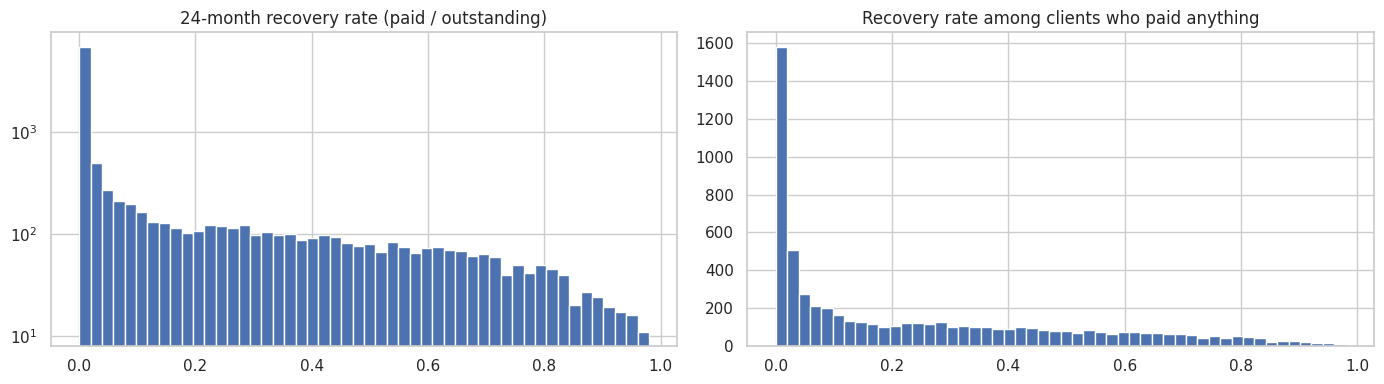

In [9]:
print(f"Share of clients with zero recovery in 24 months: {(full.paid_total == 0).mean():.1%}")
display(full.recovery_rate.describe(percentiles=[.25, .5, .75, .9, .95, .99]).to_frame("recovery_rate_24m").T)

top10 = full.paid_total.sort_values(ascending=False)
top10_share = top10.head(int(len(top10) * 0.1)).sum() / top10.sum()
print(f"Top 10% of clients bring {top10_share:.1%} of all recovered money")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(full.recovery_rate, bins=50)
axes[0].set_title("24-month recovery rate (paid / outstanding)")
axes[0].set_yscale("log")
pos = full[full.paid_total > 0]
axes[1].hist(pos.recovery_rate, bins=50)
axes[1].set_title("Recovery rate among clients who paid anything")
plt.tight_layout(); savefig("recovery_rate_distribution"); plt.show()

,cum_rate_all_cohorts,cum_rate_full_cohorts,share_of_24m_collected
3,0.026,0.027,0.217
6,0.048,0.051,0.411
9,0.068,0.071,0.574
12,0.084,0.088,0.712
18,0.108,0.112,0.911
24,0.119,0.123,1.000


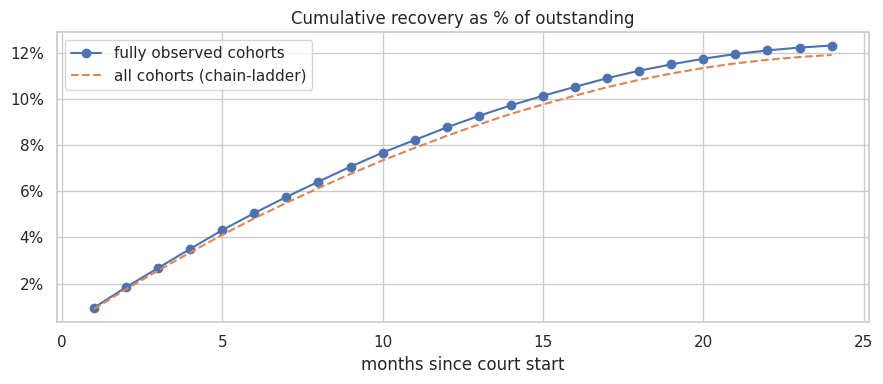

In [10]:
monthly_all = pd.Series({k: cl.loc[cl.months_obs >= k, PAY_COLS[k - 1]].sum()
                            / cl.loc[cl.months_obs >= k, "outst"].sum()
                         for k in range(1, HORIZON + 1)})
monthly_full = full[PAY_COLS].sum() / full.outst.sum()
monthly_full.index = range(1, HORIZON + 1)

curve = pd.DataFrame({"cum_rate_all_cohorts": monthly_all.cumsum(),
                      "cum_rate_full_cohorts": monthly_full.cumsum()})
curve["share_of_24m_collected"] = curve.cum_rate_full_cohorts / curve.cum_rate_full_cohorts.iloc[-1]
display(curve.loc[[3, 6, 9, 12, 18, 24]])

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(curve.index, curve.cum_rate_full_cohorts, marker="o", label="fully observed cohorts")
ax.plot(curve.index, curve.cum_rate_all_cohorts, ls="--", label="all cohorts (chain-ladder)")
ax.set(title="Cumulative recovery as % of outstanding", xlabel="months since court start")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
ax.legend(); plt.tight_layout(); savefig("recovery_curve"); plt.show()

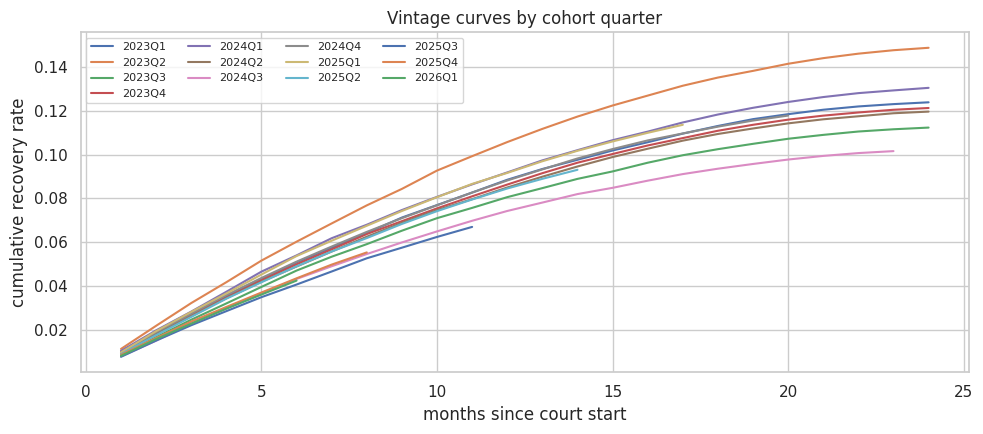

In [11]:
cl["cohort_q"] = cl.PERIOD_DT.dt.to_period("Q").astype(str)
vint = {}
for q, g in cl.groupby("cohort_q"):
    max_k = g.months_obs.min()
    vint[q] = (g[PAY_COLS[:max_k]].sum() / g.outst.sum()).cumsum().values

fig, ax = plt.subplots(figsize=(10, 4.5))
for q, v in vint.items():
    ax.plot(range(1, len(v) + 1), v, label=q)
ax.set(title="Vintage curves by cohort quarter", xlabel="months since court start", ylabel="cumulative recovery rate")
ax.legend(ncol=4, fontsize=8); plt.tight_layout(); savefig("vintage_curves"); plt.show()

## 7. Economics of the current practice ("sue everyone")

In [12]:
tot_rec, tot_cost = full.paid_total.sum(), full.court_cost.sum()
print(f"Recovered in 24m:   {tot_rec:>14,.0f} GEL")
print(f"Court costs:        {tot_cost:>14,.0f} GEL")
print(f"Net result:         {tot_rec - tot_cost:>14,.0f} GEL")
print(f"Profitable cases:   {full.profitable.mean():.1%}")
oracle = full.loc[full.net_value > 0, "net_value"].sum()
print(f"Perfect-foresight upper bound (sue only profitable): {oracle:,.0f} GEL")

cost_per_loan = FIXED_COST * full.n_loans + VAR_COST_RATE * full.outst
print(f"\nNet result if fixed fee is per loan: {(full.paid_total - cost_per_loan).sum():,.0f} GEL")

Recovered in 24m:        9,992,496 GEL
Court costs:            13,897,459 GEL
Net result:             -3,904,963 GEL
Profitable cases:   18.9%
Perfect-foresight upper bound (sue only profitable): 5,950,935 GEL

Net result if fixed fee is per loan: -10,972,463 GEL


,clients,mean_outst,mean_recovery_rate,profitable_share,net_total,breakeven_rate
outst_bucket,,,,,,
"(27.229, 855.712]",1156,497.166,0.155,0.010,"-546,317.523",1.106
"(855.712, 1576.082]",1156,"1,207.139",0.148,0.108,"-512,127.296",0.514
"(1576.082, 2436.781]",1156,"1,993.906",0.133,0.167,"-497,663.937",0.351
"(2436.781, 3349.38]",1156,"2,890.110",0.131,0.197,"-473,893.323",0.273
"(3349.38, 4451.725]",1156,"3,882.732",0.126,0.215,"-462,567.330",0.229
"(4451.725, 5839.356]",1156,"5,128.269",0.131,0.237,"-390,184.263",0.197
"(5839.356, 7597.814]",1156,"6,679.503",0.117,0.228,"-439,356.321",0.175
"(7597.814, 10320.828]",1156,"8,870.926",0.116,0.224,"-410,904.940",0.156
"(10320.828, 15811.272]",1156,"12,700.518",0.125,0.258,"-206,258.394",0.139


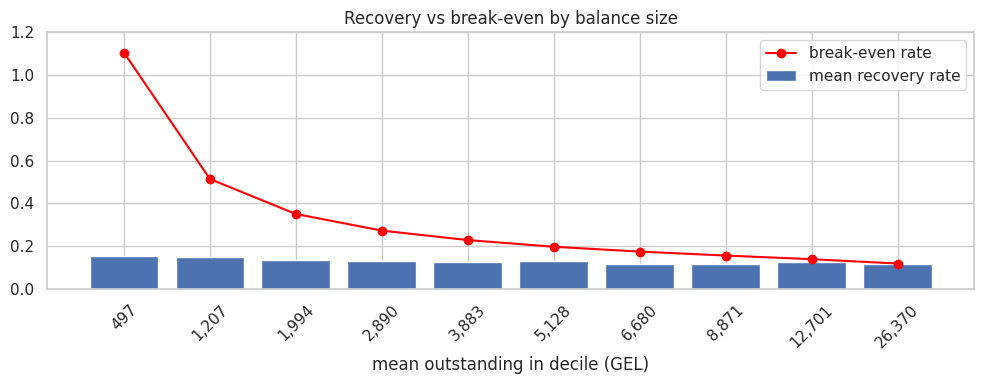

In [13]:
full["outst_bucket"] = pd.qcut(full.outst, 10)
eco = full.groupby("outst_bucket", observed=True).agg(
    clients=("CLIENT_KEY", "size"),
    mean_outst=("outst", "mean"),
    mean_recovery_rate=("recovery_rate", "mean"),
    profitable_share=("profitable", "mean"),
    net_total=("net_value", "sum"),
)
eco["breakeven_rate"] = (FIXED_COST + VAR_COST_RATE * eco.mean_outst) / eco.mean_outst
display(eco)

fig, ax = plt.subplots(figsize=(10, 4))
x = range(len(eco))
ax.bar(x, eco.mean_recovery_rate, label="mean recovery rate")
ax.plot(x, eco.breakeven_rate, color="red", marker="o", label="break-even rate")
ax.set_xticks(x); ax.set_xticklabels([f"{v:,.0f}" for v in eco.mean_outst], rotation=45)
ax.set(xlabel="mean outstanding in decile (GEL)", ylim=(0, 1.2), title="Recovery vs break-even by balance size")
ax.legend(); plt.tight_layout(); savefig("breakeven_by_balance"); plt.show()

## 8. Feature dictionary review

In [14]:
display(fdict.groupby("group").agg(n_features=("column", "size"),
                                   units=("unit", lambda s: ", ".join(sorted(s.unique())))))

,n_features,units
group,,
account balances,7,"GEL, ratio 0-1"
credit bureau history,8,"count, ratio 0-1, score"
declared income,4,"0/1, GEL, ratio 0-1"
digital channel usage,6,"0/1, count, ratio 0-1"
recent credit applications,8,"0/1, count, ratio 0-1"
repayment history on other loans,8,"count, ratio 0-1"
transaction activity,9,"GEL, count, ratio 0-1"


## 9. Feature data quality vs the dictionary

In [15]:
d = fdict.set_index("column")
issues = []
for c in FEATURES:
    s, unit, desc = feat[c], d.loc[c, "unit"], d.loc[c, "description"]
    if s.isna().any():
        issues.append((c, "missing values", f"{s.isna().mean():.1%}"))
    if s.nunique(dropna=True) <= 1:
        issues.append((c, "constant", f"single value {s.dropna().unique()}"))
    if unit == "ratio 0-1" and ((s < 0) | (s > 1)).any():
        issues.append((c, "ratio outside [0,1]", f"{((s < 0) | (s > 1)).mean():.1%}"))
    if unit == "0/1" and not s.dropna().isin([0, 1]).all():
        issues.append((c, "binary not in {0,1}", ""))
    if unit in ("GEL", "count") and (s < 0).any():
        issues.append((c, "negative values", f"{(s < 0).mean():.1%}"))
    if "out of the last 12" in desc and (s > 12).any():
        issues.append((c, "exceeds 12 months in a 12-month window", f"{(s > 12).mean():.1%} of rows, max {s.max():.0f}"))
    if "after enforcement" in desc.lower():
        issues.append((c, "POST-ENFORCEMENT INFO → LEAKAGE", desc))

issues = pd.DataFrame(issues, columns=["feature", "issue", "detail"])
display(issues)

,feature,issue,detail
0,feature_011,missing values,86.2%
1,feature_026,exceeds 12 months in a 12-month window,"92.1% of rows, max 110"
2,feature_039,missing values,30.6%
3,feature_045,POST-ENFORCEMENT INFO → LEAKAGE,Payment-arrangement and restructuring requests...
4,feature_050,constant,single value [1]


In [16]:
bad_window = (feat.feature_043 > feat.feature_044).mean()
print(f"Applications in 3 months (043) > applications in 12 months (044): {bad_window:.1%} of rows")
print(feat[["feature_043", "feature_044"]].mean().rename("mean").to_frame().T)

corr = feat[FEATURES].corr(method="spearman")
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack()
         .rename("spearman").reset_index().rename(columns={"level_0": "a", "level_1": "b"}))
high = pairs[pairs.spearman.abs() > 0.7].sort_values("spearman", key=abs, ascending=False)
high = high.assign(desc_a=high.a.map(d.description), desc_b=high.b.map(d.description))
print("\nFeature pairs with |Spearman| > 0.7:")
display(high)

print("Two payroll measures (014 6m vs 040 12m) should agree, Spearman =",
      round(corr.loc["feature_014", "feature_040"], 3))

Applications in 3 months (043) > applications in 12 months (044): 76.0% of rows
      feature_043  feature_044
mean        5.393        1.642

Feature pairs with |Spearman| > 0.7:


,a,b,spearman,desc_a,desc_b
663,feature_017,feature_033,1.000,Number of credit facilities closed with no del...,Number of credit facilities closed with no del...
98,feature_003,feature_007,0.927,"Total credit turnover across all accounts, mon...","Total debit turnover across all accounts, mont..."
1007,feature_031,feature_034,0.924,Credit bureau score at the last refresh before...,Internal behavioural score at the last monthly...


Two payroll measures (014 6m vs 040 12m) should agree, Spearman = 0.041


In [17]:
fm = full.merge(feat, on=["CLIENT_KEY", "PERIOD"], how="left")
for c in ["feature_011", "feature_039"]:
    t = fm.groupby(fm[c].isna().map({True: "missing", False: "present"})).agg(
        clients=("recovery_rate", "size"), mean_recovery=("recovery_rate", "mean"),
        profitable_share=("profitable", "mean"))
    print(c, "-", d.loc[c, "description"]); display(t)

feature_011 - Average end-of-month savings and deposit balance, 6 months. Populated only for customers holding a deposit or savings product.


,clients,mean_recovery,profitable_share
feature_011,,,
missing,9904,0.118,0.173
present,1656,0.198,0.289


feature_039 - Declared monthly income stated at the client's last credit application.


,clients,mean_recovery,profitable_share
feature_039,,,
missing,3490,0.080,0.110
present,8070,0.151,0.224


## 10. First signals: features vs recovery (fully observed cohorts)

,spearman_recovery_rate,spearman_profitable,group,description
feature_045,0.580,0.553,recent credit applications,Payment-arrangement and restructuring requests...
feature_031,0.170,0.150,credit bureau history,Credit bureau score at the last refresh before...
feature_034,0.167,0.152,credit bureau history,Internal behavioural score at the last monthly...
feature_019,-0.142,-0.132,repayment history on other loans,Share of scheduled instalments paid late over ...
feature_011,0.140,0.124,account balances,Average end-of-month savings and deposit balan...
feature_012,0.127,0.120,account balances,Maximum end-of-day total balance across all ac...
feature_021,-0.108,-0.088,repayment history on other loans,Number of times 30+ days past due on any facil...
feature_018,0.105,0.097,repayment history on other loans,Number of active loans other than the enforced...
feature_014,0.098,0.099,account balances,"Average payroll credit into the account, 6 mon..."
feature_017,0.097,0.097,repayment history on other loans,Number of credit facilities closed with no del...


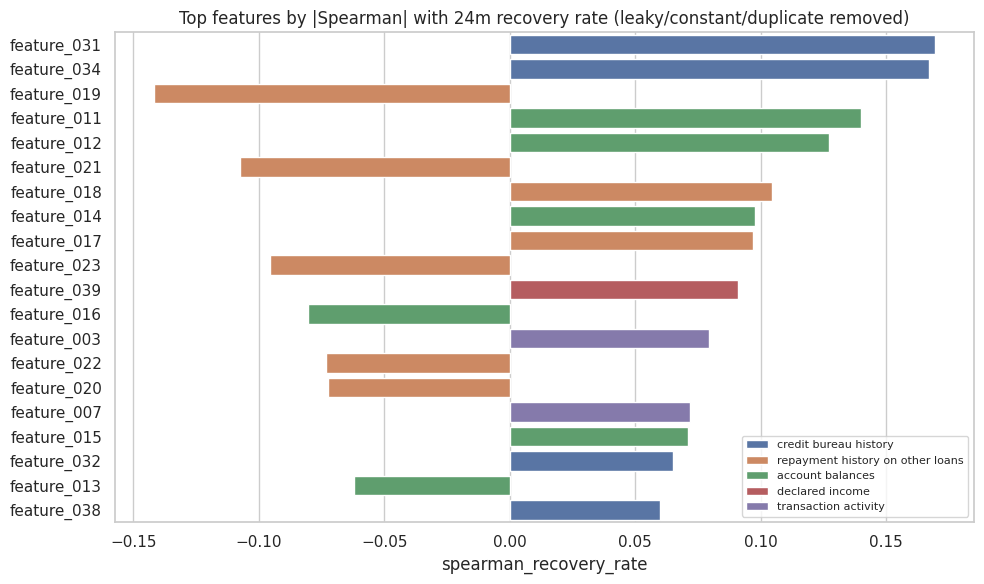

In [18]:
sig = pd.DataFrame({
    "spearman_recovery_rate": fm[FEATURES].corrwith(fm.recovery_rate, method="spearman"),
    "spearman_profitable": fm[FEATURES].corrwith(fm.profitable, method="spearman"),
}).join(d[["group", "description"]])
sig = sig.reindex(sig.spearman_recovery_rate.abs().sort_values(ascending=False).index)
display(sig.head(15))

plot = sig.drop(index=["feature_045", "feature_050", "feature_033"], errors="ignore").head(20)
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=plot.reset_index(), y="index", x="spearman_recovery_rate", hue="group", dodge=False, ax=ax)
ax.set(title="Top features by |Spearman| with 24m recovery rate (leaky/constant/duplicate removed)", ylabel="")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); savefig("univariate_signal"); plt.show()

In [19]:
print("feature_045:", d.loc["feature_045", "description"])
display(fm.groupby("feature_045").agg(clients=("recovery_rate", "size"),
                                      mean_recovery=("recovery_rate", "mean")).T)

feature_045: Payment-arrangement and restructuring requests registered on the client's collections file in the 12 months after enforcement start.


feature_045,0,1,2,3,4,5,6,7,8,9,10,11
clients,482.000,"1,615.000","2,985.000","2,905.000","1,603.000",928.000,539.000,318.000,144.000,35.000,5.000,1.000
mean_recovery,0.009,0.011,0.024,0.055,0.158,0.361,0.554,0.683,0.758,0.858,0.910,0.918


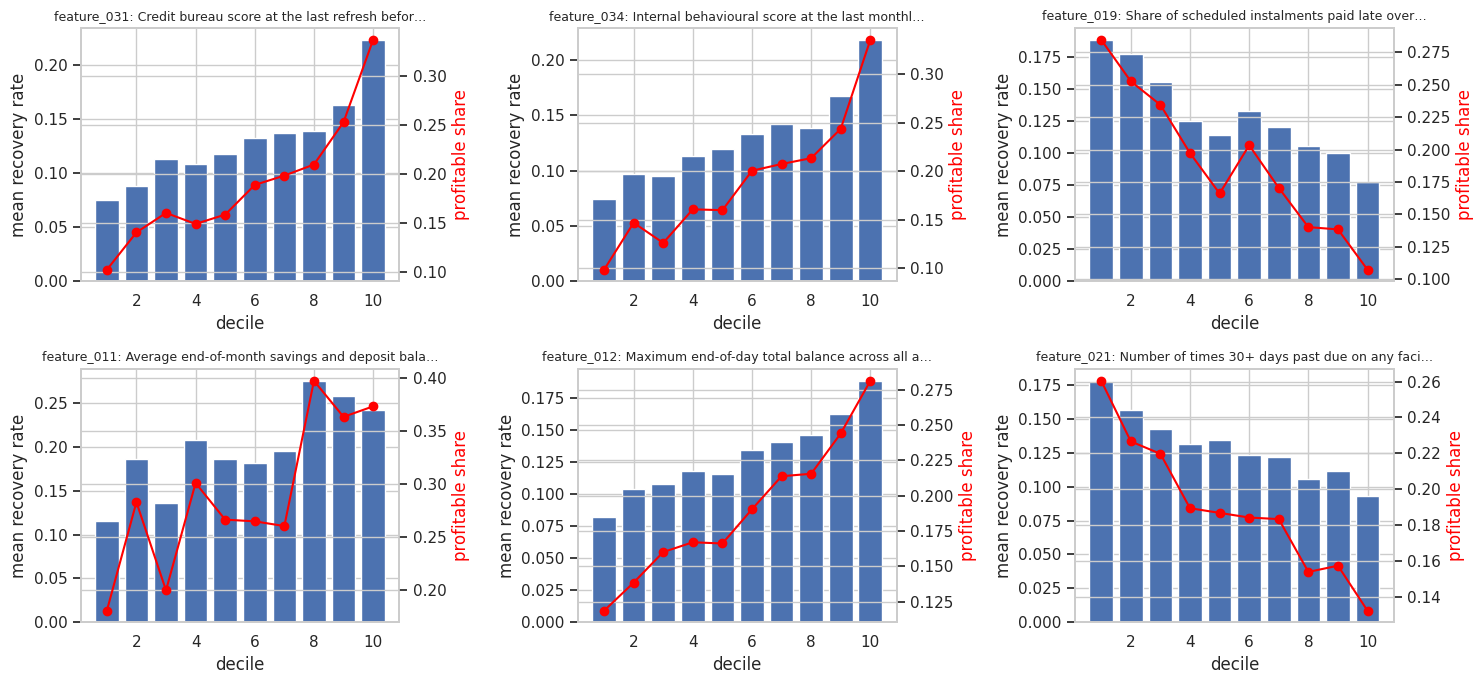

In [20]:
top = [f for f in plot.index[:6]]
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, c in zip(axes.ravel(), top):
    b = pd.qcut(fm[c].rank(method="first"), 10, labels=False)
    g = fm.groupby(b).agg(mean_rr=("recovery_rate", "mean"), prof=("profitable", "mean"))
    ax.bar(g.index + 1, g.mean_rr)
    ax2 = ax.twinx(); ax2.plot(g.index + 1, g.prof, color="red", marker="o")
    ax.set_title(f"{c}: {d.loc[c, 'description'][:45]}…", fontsize=9)
    ax.set_xlabel("decile"); ax.set_ylabel("mean recovery rate"); ax2.set_ylabel("profitable share", color="red")
plt.tight_layout(); savefig("top_feature_deciles"); plt.show()

## 11. Stability over time

In [21]:
def psi(base, current, bins=10):
    base, current = base.dropna(), current.dropna()
    edges = np.unique(np.quantile(base, np.linspace(0, 1, bins + 1)))
    if len(edges) < 3:
        return np.nan
    edges[0], edges[-1] = -np.inf, np.inf
    b = np.histogram(base, edges)[0] / len(base)
    c = np.histogram(current, edges)[0] / len(current)
    b, c = np.clip(b, 1e-4, None), np.clip(c, 1e-4, None)
    return float(np.sum((c - b) * np.log(c / b)))

feat["PERIOD_DT"] = pd.to_datetime(feat.PERIOD, format="%Y/%m")
early = feat[feat.PERIOD_DT < "2024-01-01"]
late = feat[feat.PERIOD_DT >= "2025-07-01"]
psi_tab = pd.Series({c: psi(early[c], late[c]) for c in FEATURES}, name="PSI").sort_values(ascending=False)
print("PSI 2023 cohorts vs 2025H2+ cohorts (>0.1 moderate, >0.25 major shift):")
display(psi_tab.head(10).to_frame())

trend = full.groupby(full.PERIOD_DT.dt.to_period("Q")).agg(
    mean_recovery=("recovery_rate", "mean"), profitable_share=("profitable", "mean"), clients=("CLIENT_KEY", "size"))
display(trend)

PSI 2023 cohorts vs 2025H2+ cohorts (>0.1 moderate, >0.25 major shift):


,PSI
feature_007,0.228
feature_011,0.010
feature_045,0.007
feature_043,0.005
feature_006,0.004
feature_018,0.003
feature_002,0.003
feature_034,0.003
feature_031,0.003
feature_025,0.003


,mean_recovery,profitable_share,clients
PERIOD_DT,,,
2023Q1,0.133,0.203,1386
2023Q2,0.145,0.202,1452
2023Q3,0.126,0.187,1569
2023Q4,0.130,0.188,1794
2024Q1,0.132,0.194,1851
2024Q2,0.128,0.191,2092
2024Q3,0.114,0.160,1416


## 12. Save the clean analysis table

In [22]:
DROP_FEATURES = ["feature_045", "feature_050", "feature_033"]
keep_feats = [c for c in FEATURES if c not in DROP_FEATURES]

out = cl.drop(columns=["cohort_q"]).merge(feat[["CLIENT_KEY", "PERIOD"] + keep_feats],
                                          on=["CLIENT_KEY", "PERIOD"], how="left")
out["feature_011_missing"] = out.feature_011.isna().astype(int)
out["feature_039_missing"] = out.feature_039.isna().astype(int)

try:
    out_path = PROC_DIR / "client_period_unsecured.parquet"
    out.to_parquet(out_path, index=False)
except ImportError:
    out_path = PROC_DIR / "client_period_unsecured.csv"
    out.to_csv(out_path, index=False)
print(f"Saved {out.shape[0]:,} rows × {out.shape[1]} cols to {out_path.relative_to(PROJECT_DIR)}")
print(f"Fully observed rows (training target ready): {out.fully_observed.sum():,}")

Saved 27,029 rows × 89 cols to data/processed/client_period_unsecured.parquet
Fully observed rows (training target ready): 11,560


## 13. Summary and decisions for the next notebooks

**Data**
- 70,173 loans, 22,000 clients, **29,763 client × court-period pairs**; 7,763 clients were litigated in two periods,
  so splits will be out-of-time and grouped by client. Features join 1:1 with no gaps.
- Data snapshot is **2026-08**. Recovery is cleanly right-censored; the 20 cohorts from 2023-01 to 2024-08 have the full 24 months.
- Scope: unsecured loans only → 27,029 client-periods, of which **11,560 are fully observed**.
  13% of client-periods are mixed secured/unsecured and are kept with a flag.

**Target behaviour**
- 46.7% of clients pay nothing in 24 months; the top 10% bring about 75% of all recovered money.
- Only ~71% of 24-month recovery arrives by month 12 (41% by month 6). The curve gives development factors for censored cohorts and an early pilot readout.
- **"Sue everyone" loses about 3.9M GEL** on fully observed cohorts (10.0M recovered vs 13.9M costs); only 18.9% of cases are profitable.
  Suing only the profitable cases would have earned about +6.0M GEL. That ~9.9M gap is the opportunity the model targets.
- The recovery rate barely depends on balance size (~12–15%), but the break-even rate falls from >100% for the smallest balances
  to ~12% for the largest. Balance size enters the decision through cost.
- If the 500 GEL fee were charged per loan rather than per client, losses would be about 11M GEL, so this assumption must be confirmed with the business.

**Features**
- Dropped: `feature_045` (measured *after* enforcement → leakage; Spearman 0.58 with recovery, far above any legitimate feature),
  `feature_050` (constant), `feature_033` (identical to `feature_017`).
- Flagged to data owners: `feature_043`/`044` (3-month count exceeds 12-month count in 76% of rows), `feature_026` (92% above its 12-month maximum),
  `feature_014` vs `feature_040` (payroll measures with Spearman ≈ 0.04).
- Informative missingness: clients with deposits (`feature_011`) or declared income (`feature_039`) recover clearly more → missing-flags added.
- Strongest legitimate signals are modest (|Spearman| ≤ 0.17): bureau and behavioural scores (031, 034, correlated 0.92), late-payment share (019),
  deposits and balances (011, 012), 30+ DPD history (021), payroll (014). Expect a moderate-Gini model; the value comes from ranking plus cost-aware decisions.
- Stability: features are stable over time except `feature_007` (debit turnover, PSI ≈ 0.23), which needs monitoring.
